# 🚇 Metro Air Compressor Failure Prediction (MetroPT-3)

## Ye project kya hai?
Porto (Portugal) ki metro train ke **Air Compressor** ka real sensor data hai (Feb-Sep 2020). Compressor kharab ho to brake aur doors jaise system fail ho sakte hain.

## Problem Statement
Sensor readings dekh kar predict karna ki compressor **normal (0)** hai ya **failure window (1)** me hai.

## Kyun kar rahe hain?
Predictive maintenance me kharabi aane se *pehle* pakadne se cost aur downtime bachta hai.

## Kya-kya karenge?
1. Data load karke 5-minute average me chhota karenge (15 lakh rows -> kam rows)
2. Failure windows se `failure` target column banayenge
3. Rolling features banayenge (pichhle 1 ghante ka mean aur std)
4. **Time-based split** karenge (random nahi, warna data leakage hoga)
5. 5 models compare karenge: Logistic Regression, KNN, Gaussian NB, Decision Tree, Random Forest
6. K-Means se unsupervised anomaly detection karenge
7. Har model ki **Accuracy, Precision, Recall, F1, PR-AUC** nikalenge aur dikhayenge ki Accuracy dhokha kyun deti hai
8. Best model ke important features dekhenge

## Kya nahi karenge?
- **Sirf Accuracy pe bharosa nahi**, kyunki failure rows bahut kam hain. Accuracy dikhayenge, lekin model Recall, F1, PR-AUC se chunenge.
- **Linear Regression nahi**, kyunki ye numeric value predict karta hai, hamara target 0/1 hai.
- **Hierarchical Clustering nahi**, kyunki itne bade data pe memory khatam ho jati hai.

In [81]:
import pandas as pd  # data table handle karne ke liye
import numpy as np  # numeric calculation ke liye
import matplotlib.pyplot as plt  # graph banane ke liye
import seaborn as sns  # graph ko sundar banane ke liye
from sklearn.pipeline import make_pipeline  # scaler aur model ko jodne ke liye
from sklearn.preprocessing import StandardScaler  # features ko same scale pe laane ke liye
from sklearn.linear_model import LogisticRegression  # model 1
from sklearn.neighbors import KNeighborsClassifier  # model 2
from sklearn.naive_bayes import GaussianNB  # model 3
from sklearn.tree import DecisionTreeClassifier  # model 4
from sklearn.ensemble import RandomForestClassifier  # model 5
from sklearn.cluster import KMeans  # anomaly detection ke liye
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score, confusion_matrix  # saare score nikalne ke liye
sns.set_style('whitegrid')  # graph ka clean style set karo

Data load and Describe

In [82]:
raw = pd.read_csv('MetroPT3(AirCompressor).csv')  # CSV padho (abhi timestamp ko normal column rehne do)
raw = raw.drop(columns=['Unnamed: 0'], errors='ignore')  # faltu index column hata do (na ho to bhi error nahi aayega)
raw['timestamp'] = pd.to_datetime(raw['timestamp'], dayfirst=True)  # text ko asli date-time banao (dayfirst = pehle din, phir mahina)
raw = raw.set_index('timestamp').sort_index()  # time ko index banao aur order me lagao
print(raw.shape, raw.index.min(), raw.index.max())  # rows-columns aur date range check karo
df = raw.resample('5min').mean().dropna()  # har 5 minute ka average lo aur khali rows hata do
print(df.shape)  # naya size dekho (data ab bahut chhota hai)

(1048575, 15) 2020-02-01 00:00:00 2020-06-26 13:14:00
(35175, 15)


In [83]:
df.shape

(35175, 15)

In [84]:
df.columns

Index(['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature',
       'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS',
       'Pressure_switch', 'Oil_level', 'Caudal_impulses'],
      dtype='str')

In [85]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 35175 entries, 2020-02-01 00:00:00 to 2020-06-26 13:10:00
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   TP2              35175 non-null  float64
 1   TP3              35175 non-null  float64
 2   H1               35175 non-null  float64
 3   DV_pressure      35175 non-null  float64
 4   Reservoirs       35175 non-null  float64
 5   Oil_temperature  35175 non-null  float64
 6   Motor_current    35175 non-null  float64
 7   COMP             35175 non-null  float64
 8   DV_eletric       35175 non-null  float64
 9   Towers           35175 non-null  float64
 10  MPG              35175 non-null  float64
 11  LPS              35175 non-null  float64
 12  Pressure_switch  35175 non-null  float64
 13  Oil_level        35175 non-null  float64
 14  Caudal_impulses  35175 non-null  float64
dtypes: float64(15)
memory usage: 4.3 MB


In [86]:
df.describe()

,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
count,35175.000000,35175.000000,35175.000000,35175.000000,35175.000000,35175.000000,35175.000000,35175.000000,35175.000000,35175.000000,35175.000000,35175.000000,35175.000000,35175.000000,35175.00000
mean,1.458296,8.956295,7.445326,0.085057,8.956875,61.113266,1.994604,0.822657,0.172388,0.914298,0.816905,0.003134,0.987447,0.982780,0.90925
std,2.552025,0.574852,2.734793,0.420012,0.574347,6.493700,1.997405,0.299816,0.295439,0.142462,0.307745,0.052481,0.046377,0.097578,0.27415
min,-0.025000,1.023000,-0.015200,-0.030867,1.005000,18.700000,0.020446,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,0.00000
25%,-0.013419,8.511133,6.497567,-0.023067,8.512467,56.379167,0.041694,0.709677,0.000000,0.833333,0.700000,0.000000,1.000000,1.000000,1.00000
50%,-0.011419,8.942600,8.587867,-0.020800,8.943867,60.480833,1.424000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.00000
75%,2.559646,9.413575,9.157900,-0.017200,9.413867,65.305833,3.805958,1.000000,0.300000,1.000000,1.000000,0.000000,1.000000,1.000000,1.00000
max,10.075533,10.161667,10.144000,2.507548,10.158667,82.842500,6.201500,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


Target column banana

In [87]:
df['failure'] = 0
df.loc['2020-04-18 00:00':'2020-04-18 23:59', 'failure'] = 1
df.loc['2020-05-29 23:30':'2020-05-30 06:00', 'failure'] = 1
df.loc['2020-06-05 10:00':'2020-06-07 14:30', 'failure'] = 1
df.loc['2020-07-15 14:30':'2020-07-15 19:00', 'failure'] = 1
print(df['failure'].value_counts(normalize=True))
print(df['failure'].sum())

# # Note: Is code me 'failure' column banakar, kuch specific time slots me jab machine/system down tha tab target 1 mark kiya gaya hai (baaki sab 0 hai).
# Yeh output dikha raha hai ki 97.3% time sab normal (0) tha, aur sirf 2.7% time (total 941 intervals) me actual failure (1) hua tha.
# "Maine historical breakdown timestamps ke basis par target column failure ko binary label (0 for normal, 1 for failure) kiya hai, jahan failure rate lagbhag 2.7% (~941 instances) hai."

failure
0    0.973248
1    0.026752
Name: proportion, dtype: float64
941


Graph 1: failure windows)

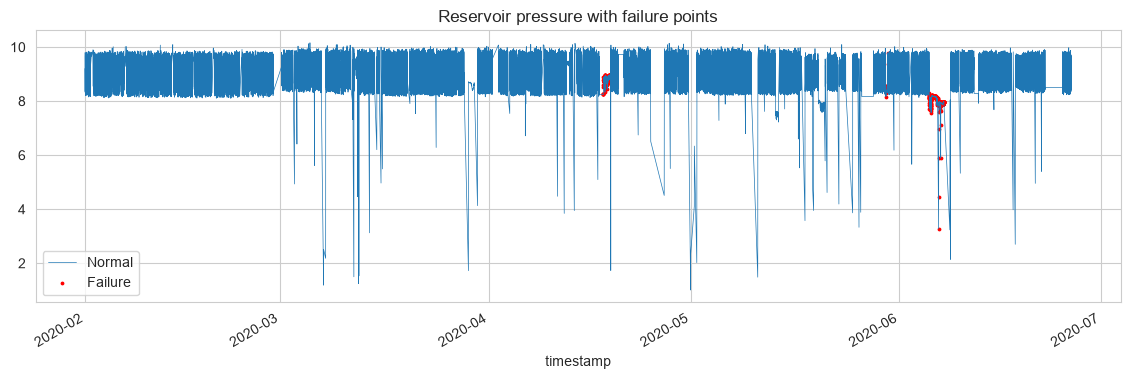

In [88]:
fail = df[df['failure'] == 1]  # 1. Sirf failure wale (1) rows ka subset alag kar rahe hain

ax = df['Reservoirs'].plot(figsize=(14, 4), lw=0.5, label='Normal')  # 2. Reservoir pressure ka main blue line graph plot kiya

ax.scatter(fail.index, fail['Reservoirs'], color='red', s=3, label='Failure')  # 3. Failure ke timestamps par red dots dikhane ke liye scatter plot use kiya[cite: 2]

ax.set_title('Reservoir pressure with failure points')  # 4. Graph ka main title set kiya aur legend/show se display karwaya[cite: 2]
ax.legend()  
plt.show()

# Graph se clear visual proof milta hai ki normal condition me Reservoir Pressure 8-10 par rehta hai, aur Machine Breakdown/Failure ke time par pressure sharp drop hota hai.

Feature engineering

In [89]:
X = df.drop(columns=['failure'])  # target ko features se alag karo (leakage se bachne ke liye)
X_mean = X.rolling(12).mean().add_suffix('_mean')  # pichhli 12 rows (5 min x 12 = 1 ghanta) ka average
X_std = X.rolling(12).std().add_suffix('_std')  # pichhle 1 ghante ka std (kitna upar-neeche ho raha hai)
X_all = pd.concat([X, X_mean, X_std], axis=1).dropna()  # original + mean + std jodo aur shuru ki khali rows hata do
y_all = df.loc[X_all.index, 'failure']  # unhi rows ka target nikalo
print(X_all.shape)  # features ka size dekho

# "Maine 1-hour rolling window ($12 \text{ steps}$) ka use karke Moving Average aur Standard Deviation features generate kiye hain taaki model sensor data ka trend aur volatility learn kar sake, aur shuru ki empty rows ko dropna() se filter karke final feature matrix X_all banaya hai." 

(35164, 45)


Time-based split

In [90]:
X_train, y_train = X_all.loc[:'2020-06-01'], y_all.loc[:'2020-06-01']     # 1 June tak ka data train ke liye (2 failures)
X_test, y_test = X_all.loc['2020-06-02':], y_all.loc['2020-06-02':]       # uske baad ka data test ke liye (2 failures)
print("Train me total failures (1s):", y_train.sum())                     # dono me failure rows ki ginti dekho (dono 0 se zyada honi chahiye)
print("Test me total failures (1s):", y_test.sum())                       # dono me failure rows ki ginti dekho (dono 0 se zyada honi chahiye)
print("Test data ka failure mean/proportion:", y_test.mean())             # test me failure ka percent (ye PR-AUC ka random baseline hai)

Train me total failures (1s): 367
Test me total failures (1s): 574
Test data ka failure mean/proportion: 0.09191353082465972


(Models + functions)

In [91]:
models = pd.Series({  # saare models ek Series me (naam -> model)
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000)),  # scaling ke saath baseline model
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),  # KNN distance pe chalta hai isliye scaling zaroori
    'Gaussian NB': GaussianNB(),  # simple probability wala model
    'Decision Tree': DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42),  # depth limit se overfitting kam
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', n_jobs=-1, random_state=42)})  # bahut saare trees ka combination

def get_metrics(y_true, pred, score):  # saare scores nikalne wala function (baar-baar use hoga)
    return pd.Series({'Accuracy': accuracy_score(y_true, pred),  # kul predictions me se kitne sahi (imbalance me dhokha de sakti hai)
                      'Precision': precision_score(y_true, pred, zero_division=0),  # jitne failure bole unme se kitne sahi
                      'Recall': recall_score(y_true, pred, zero_division=0),  # asli failures me se kitne pakde
                      'F1': f1_score(y_true, pred, zero_division=0),  # precision aur recall ka balance
                      'PR-AUC': average_precision_score(y_true, score)})  # imbalance me sabse reliable score

def evaluate(model):  # ek model train aur test karne wala function
    model.fit(X_train, y_train)  # train data pe model ko seekhao
    return get_metrics(y_test, model.predict(X_test), model.predict_proba(X_test)[:, 1])  # test data pe score wapas do

# "Maine 5 classifiers ka ek pipeline setup kiya hai aur ek automated evaluation function banaya hai jo imbalanced dataset ke liye reliable metrics (jaise PR-AUC) calculate karta hai."

## 📊 Train vs Test Score Comparison

**Ye step kyun?**
Model ko sirf test data pe check karna kaafi nahi hai. Train aur test dono pe score nikalke compare karte hain, taaki **overfitting** pakad sakein.

| Train score | Test score | Matlab |
|---|---|---|
| Ucha | Ucha | Model ne achha seekha ✅ |
| Ucha | Bahut kam | **Overfitting**: model ne ratta maara, seekha nahi ❌ |
| Kam | Kam | **Underfitting**: model kamzor hai |

**Kya karenge?**
1. Pehle `evaluate` se models train honge aur **test** score nikalega
2. Phir wahi trained models pe **train** score nikalenge
3. Dono ka gap (`train F1 - test F1`) dekhenge. **Gap 0 ke paas = achha, bada gap = overfitting.**

**Dhyan rakhna:** Accuracy yahan bhi dhokha degi, isliye asli faisla Recall, F1 aur PR-AUC se karenge.

(Train vs Test score)

In [92]:
def evaluate_train(model):  # train data pe score nikalne wala function (model pehle se trained hona chahiye)
    return get_metrics(y_train, model.predict(X_train), model.predict_proba(X_train)[:, 1])  # train data pe score wapas do

results = models.apply(evaluate)  # har model ko train karo aur TEST data pe score nikalo
train_results = models.apply(evaluate_train)  # wahi trained models ka TRAIN data pe score nikalo
print('--- TRAIN scores ---')  # heading
print(train_results.round(3))  # train ka table dekho
print('--- TEST scores ---')  # heading
print(results.round(3))  # test ka table dekho
print('--- Overfitting gap (Train F1 - Test F1) ---')  # heading
print((train_results['F1'] - results['F1']).round(3))  # gap jitna bada utna zyada overfitting
dummy_acc = 1 - y_test.mean()  # agar model sabko "normal (0)" bole to itni accuracy milti
print('Sabko 0 bolne wali accuracy:', round(dummy_acc, 3))  # ye wo accuracy hai jo bina kuch seekhe mil jati hai

--- TRAIN scores ---
                     Accuracy  Precision  Recall     F1  PR-AUC
Logistic Regression     0.987      0.499   1.000  0.666   0.475
KNN                     0.999      0.962   0.954  0.958   0.994
Gaussian NB             0.966      0.268   0.978  0.421   0.267
Decision Tree           1.000      0.976   1.000  0.988   0.976
Random Forest           0.999      0.961   1.000  0.980   1.000
--- TEST scores ---
                     Accuracy  Precision  Recall     F1  PR-AUC
Logistic Regression     0.880      0.409   0.693  0.515   0.533
KNN                     0.911      0.957   0.038  0.074   0.249
Gaussian NB             0.994      0.984   0.946  0.964   0.939
Decision Tree           0.928      0.992   0.218  0.357   0.288
Random Forest           0.913      1.000   0.054  0.102   0.643
--- Overfitting gap (Train F1 - Test F1) ---
Logistic Regression    0.151
KNN                    0.884
Gaussian NB           -0.544
Decision Tree          0.631
Random Forest          0.877
N

(K-Means anomaly detection)

In [93]:
def anomaly_score(km, scaler, X):  # anomaly score nikalne wala function (2 baar call hoga)
    return km.transform(scaler.transform(X)).min(axis=1)  # sabse paas ke cluster se distance (zyada distance = zyada anomaly)

normal = X_train[y_train == 0]  # sirf normal training data lo
scaler = StandardScaler().fit(normal)  # scaler normal data pe fit karo
km = KMeans(n_clusters=5, n_init=10, random_state=42).fit(scaler.transform(normal))  # normal behaviour ke 5 cluster banao
limit = np.percentile(anomaly_score(km, scaler, normal), 99)  # normal data ka 99th percentile = threshold
score = anomaly_score(km, scaler, X_test)  # test data ka anomaly score nikalo
pred = (score > limit).astype(int)  # threshold se upar wale = failure (1)
results.loc['K-Means (anomaly)'] = get_metrics(y_test, pred, score)  # K-Means ka result table me jodo
print(results.round(3))  # final table dekho

                     Accuracy  Precision  Recall     F1  PR-AUC
Logistic Regression     0.880      0.409   0.693  0.515   0.533
KNN                     0.911      0.957   0.038  0.074   0.249
Gaussian NB             0.994      0.984   0.946  0.964   0.939
Decision Tree           0.928      0.992   0.218  0.357   0.288
Random Forest           0.913      1.000   0.054  0.102   0.643
K-Means (anomaly)       0.901      0.260   0.044  0.075   0.205


Graph 2: model comparison

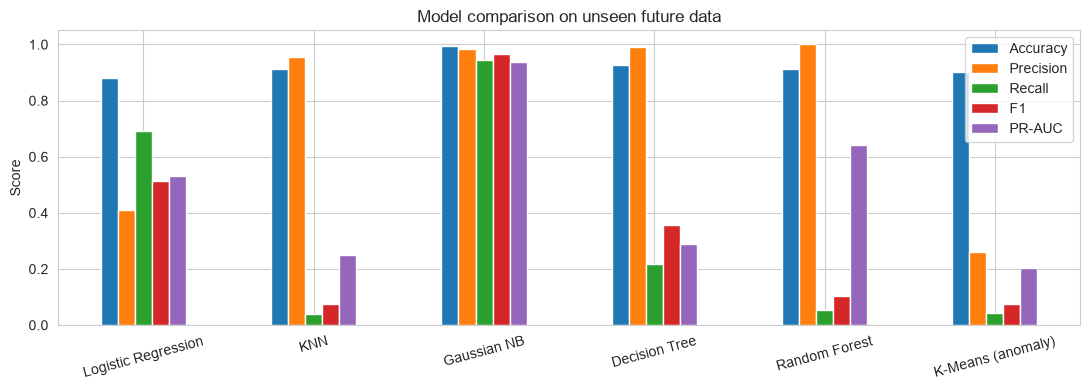

In [94]:
ax = results.plot(kind='bar', figsize=(11, 4), rot=15)  # saare models ke test scores ka bar chart
ax.set_title('Model comparison on unseen future data')  # graph ka title
ax.set_ylabel('Score')  # y axis ka naam
plt.tight_layout()  # layout adjust karo
plt.show()  # graph dikhao

(Graph 3: best model + top features)

Best Model: Gaussian NB
[[5662    9]
 [  31  543]]


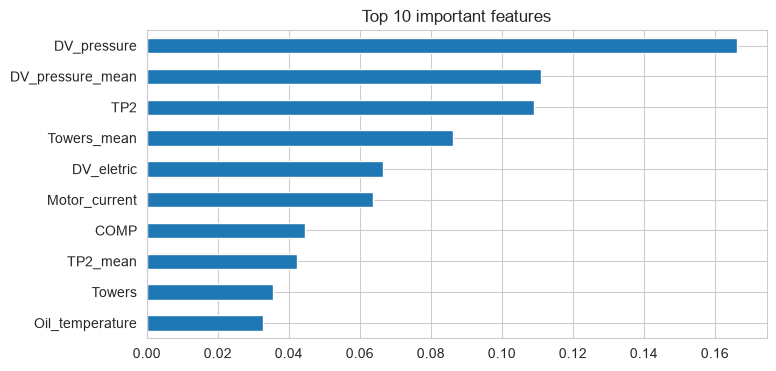

In [95]:
best = results.drop('K-Means (anomaly)')['F1'].idxmax()
print('Best Model:',best)
print(confusion_matrix(y_test, models[best].predict(X_test)))
imp = pd.Series(models['Random Forest'].feature_importances_,index=X_train.columns).nlargest(10)
imp.sort_values().plot(kind='barh',figsize=(8,4), title='Top 10 important features')
plt.show()

# ✅ Conclusion

- **Best model:** Gaussian NB (Test F1 = 0.964, PR-AUC = 0.939), par test me failure events kam hain, isliye result indicative hai.
- **Accuracy misleading hai:** sabko 0 bolne se bhi 0.908 accuracy milti hai. KNN (0.911) aur Random Forest (0.913) lagbhag utni hi hain, par unka Recall sirf 0.04-0.05 hai.
- **Overfitting (Train F1 - Test F1):** KNN (0.88), Random Forest (0.88) aur Decision Tree (0.63) ne train ke failures ratt liye. Logistic Regression ka gap sabse kam (0.15) raha, par uska Test F1 (0.515) NB se kam hai.
- **Random Forest:** PR-AUC 0.643 achha hai par F1 0.10, yani threshold tuning se sudhar sakta hai.
- **K-Means:** bina labels ke Recall sirf 0.044, kamzor raha.
- Top features: ___, ___, ___ (Cell 14 ke graph se bharo).

## Limitations aur Next Steps
- Failure events sirf 4 hain (aur kati hui file me test me sirf 1), isliye result indicative hai, final nahi.
- Hyperparameter tuning nahi ki. Aage threshold tuning, XGBoost, LSTM ya Autoencoder try kar sakte hain.